# 오탐 전수 시각 분류 (단계 2-C)

진단 노트북 셀 27에서 오탐 16개만 시각 검토 → 손가락 패턴 확인. 한계: 16개로는 전체 패턴 단정 불가.

본 노트북: 오탐 259개 전수 시각 분류로 패턴 클러스터링. 손가락 외 패턴이 있다면 처방 4(배경 풀 재구성)에 추가 항목.

## 측정 대상

- 평가 결과의 모든 FP 박스 (33장 테스트, RTMDet-tiny + synthetic_combined 모델)
- IoU < 0.3 또는 GT와 매칭 안 된 모든 예측

## 분류 방식

1. FP 박스 정보 추출 (이미지/좌표/conf/예측 클래스)
2. crop 이미지 + 주변 컨텍스트 그리드 시각
3. 패턴별 분류 — 사람 눈 검토 필요 (자동 분류 부정확 가능)
4. 패턴별 카운트 → 빈도순 정렬

## 출력

- 모든 오탐 crop 그리드 (페이지 분할)
- conf 분포, 위치 분포, 예측 클래스 분포
- 패턴 카테고리별 카운트 표

In [1]:
## 셀 1 — 셋업 + 평가 결과 경로 확인

from pathlib import Path
import json
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.patches as patches

# ── 경로 ──
ROOT = Path(r"D:\pill_detection")
EVAL_DIR = ROOT / "eval"
TEST_IMG_DIR = EVAL_DIR / "test_images"
TEST_LBL_DIR = EVAL_DIR / "test_labels" / "test_labels"

ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR = ANALYSIS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ── 한글 폰트 ──
candidates = ['Malgun Gothic', 'NanumGothic', 'Gulim']
available = {f.name for f in fm.fontManager.ttflist}
for name in candidates:
    if name in available:
        plt.rcParams['font.family'] = name
        print(f"한글 폰트: {name}")
        break
plt.rcParams['axes.unicode_minus'] = False


# ── 헬퍼 ──
def imread_kr(path):
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)


# ── 평가 결과/예측 파일 위치 자동 탐색 ──
print("\n[평가 결과 파일 탐색]")
candidates_pred = list(ANALYSIS_DIR.rglob("*pred*.json")) + \
                  list(ANALYSIS_DIR.rglob("*result*.json")) + \
                  list((ROOT / "eval").rglob("*pred*.json")) + \
                  list((ROOT / "eval").rglob("*result*.json"))
for p in candidates_pred:
    print(f"  발견: {p}")

candidates_diag = list(ANALYSIS_DIR.rglob("01_model_diagnosis.ipynb"))
for p in candidates_diag:
    print(f"  진단 노트북: {p}")


# ── 테스트 이미지/GT 카운트 ──
test_imgs = sorted(TEST_IMG_DIR.glob("*"))
test_lbls = sorted(TEST_LBL_DIR.glob("*.txt")) + sorted(TEST_LBL_DIR.glob("*.json"))
print(f"\n[테스트 데이터]")
print(f"  이미지: {len(test_imgs)}장")
print(f"  GT 라벨: {len(test_lbls)}개")
if test_imgs:
    print(f"  이미지 예시: {test_imgs[0].name}")
if test_lbls:
    print(f"  라벨 예시: {test_lbls[0].name}")

한글 폰트: Malgun Gothic

[평가 결과 파일 탐색]
  발견: D:\pill_detection\eval\rtmdet_tiny_synth_e15_seed100_results.json

[테스트 데이터]
  이미지: 33장
  GT 라벨: 33개
  이미지 예시: 게보린정 300mg_3.png
  라벨 예시: 게보린정 300mg_3.txt


## 1. 평가 결과 + GT 로드 + 자료구조 확인

평가 결과 JSON 구조 확인 후 예측 박스 / GT 박스 통합 DataFrame 생성.

GT 라벨 포맷: YOLO txt (class_id cx cy w h, 정규화 좌표). 테스트 33장 / 라벨 33개.

이 셀에서 확인할 것:
- 평가 JSON 키 구조 (image별 dict인지, 박스 리스트인지)
- 박스 좌표 형식 (xyxy / xywh / 정규화 / 픽셀)
- conf, class_id 위치

In [2]:
## 셀 3 — 평가 JSON 자료구조 확인 (추측 금지, 직접 출력)

EVAL_JSON = ROOT / "eval" / "rtmdet_tiny_synth_e15_seed100_results.json"
print(f"파일: {EVAL_JSON}")
print(f"크기: {EVAL_JSON.stat().st_size / 1024:.1f} KB\n")

with open(EVAL_JSON, "r", encoding="utf-8") as f:
    eval_data = json.load(f)

print(f"최상위 타입: {type(eval_data).__name__}")
if isinstance(eval_data, dict):
    print(f"키 개수: {len(eval_data)}")
    print(f"키 예시 (처음 3개): {list(eval_data.keys())[:3]}")
    first_key = next(iter(eval_data))
    first_val = eval_data[first_key]
    print(f"\n첫 항목 [{first_key}]")
    print(f"  타입: {type(first_val).__name__}")
    if isinstance(first_val, dict):
        print(f"  키: {list(first_val.keys())}")
        for k, v in first_val.items():
            if isinstance(v, list) and v:
                print(f"  {k}: list, 길이 {len(v)}, 첫 항목 타입 {type(v[0]).__name__}")
                if isinstance(v[0], (list, dict)):
                    print(f"    첫 항목 내용: {v[0]}")
            else:
                preview = str(v)[:200]
                print(f"  {k}: {type(v).__name__}, 값 {preview}")
    elif isinstance(first_val, list):
        print(f"  길이: {len(first_val)}")
        if first_val:
            print(f"  첫 항목: {first_val[0]}")
elif isinstance(eval_data, list):
    print(f"길이: {len(eval_data)}")
    if eval_data:
        print(f"첫 항목 타입: {type(eval_data[0]).__name__}")
        print(f"첫 항목: {eval_data[0]}")


# ── GT txt 1개 자료구조 확인 ──
print("\n\n[GT 라벨 1개 확인]")
sample_lbl = sorted(TEST_LBL_DIR.glob("*.txt"))[0]
print(f"파일: {sample_lbl.name}")
with open(sample_lbl, "r", encoding="utf-8") as f:
    lines = f.read().strip().splitlines()
print(f"줄 수: {len(lines)}")
for i, line in enumerate(lines[:5]):
    parts = line.split()
    print(f"  줄 {i}: {parts} (값 개수 {len(parts)})")


# ── 이미지 크기 1개 확인 (좌표 정규화 해제용) ──
sample_img_path = TEST_IMG_DIR / (sample_lbl.stem + sample_lbl.suffix.replace('.txt', '.png'))
if not sample_img_path.exists():
    sample_img_path = next(TEST_IMG_DIR.glob(f"{sample_lbl.stem}*"))
img = imread_kr(sample_img_path)
print(f"\n이미지 [{sample_img_path.name}] shape: {img.shape}")

파일: D:\pill_detection\eval\rtmdet_tiny_synth_e15_seed100_results.json
크기: 141.3 KB

최상위 타입: dict
키 개수: 15
키 예시 (처음 3개): ['exp_name', 'author', 'model_framework']

첫 항목 [exp_name]
  타입: str


[GT 라벨 1개 확인]
파일: 게보린정 300mg_3.txt
줄 수: 1
  줄 0: ['1', '0.509843', '0.496259', '0.562992', '0.349127'] (값 개수 5)

이미지 [게보린정 300mg_3.png] shape: (401, 254, 3)


In [3]:
## 셀 4 — 평가 JSON 전체 키 + 박스 데이터 위치 탐색

print("[최상위 키 전체]")
for k, v in eval_data.items():
    if isinstance(v, str):
        print(f"  {k}: str, '{v[:80]}'")
    elif isinstance(v, (int, float)):
        print(f"  {k}: {type(v).__name__}, {v}")
    elif isinstance(v, list):
        print(f"  {k}: list, 길이 {len(v)}")
        if v:
            print(f"    [0] 타입: {type(v[0]).__name__}")
            if isinstance(v[0], dict):
                print(f"    [0] 키: {list(v[0].keys())}")
            elif isinstance(v[0], (list, str, int, float)):
                print(f"    [0] 값: {v[0]}")
    elif isinstance(v, dict):
        print(f"  {k}: dict, 키 개수 {len(v)}")
        sub_keys = list(v.keys())[:5]
        print(f"    키 예시: {sub_keys}")
        first_sub_k = next(iter(v))
        first_sub_v = v[first_sub_k]
        print(f"    [{first_sub_k}] 타입: {type(first_sub_v).__name__}")
        if isinstance(first_sub_v, dict):
            print(f"    [{first_sub_k}] 키: {list(first_sub_v.keys())}")
        elif isinstance(first_sub_v, list):
            print(f"    [{first_sub_k}] 길이: {len(first_sub_v)}")
            if first_sub_v:
                print(f"    [{first_sub_k}][0]: {first_sub_v[0]}")
    else:
        print(f"  {k}: {type(v).__name__}")

[최상위 키 전체]
  exp_name: str, 'rtmdet_tiny_synth_e15_seed100'
  author: str, 'seungwon'
  model_framework: str, 'mmdet rtmdet_tiny'
  model_params_M: float, 4.9
  batch_size_used: int, 16
  seed: int, 100
  conf_threshold: float, 0.05
  nms_iou: float, 0.5
  best_epoch: int, 15
  ms_per_image: float, 125.5
  eval_version: str, 'v4'
  num_images: int, 33
  num_gt_bboxes: int, 47
  created_at: str, '2026-05-01T10:15:08'
  results: list, 길이 33
    [0] 타입: dict
    [0] 키: ['filename', 'gt_bboxes', 'predictions']


In [4]:
## 셀 5 — results 첫 항목 상세 확인

first_result = eval_data['results'][0]
print(f"filename: {first_result['filename']}\n")

print(f"gt_bboxes 타입: {type(first_result['gt_bboxes']).__name__}, 길이: {len(first_result['gt_bboxes'])}")
if first_result['gt_bboxes']:
    print(f"  [0] 타입: {type(first_result['gt_bboxes'][0]).__name__}")
    print(f"  [0] 내용: {first_result['gt_bboxes'][0]}")
    if isinstance(first_result['gt_bboxes'][0], dict):
        for k, v in first_result['gt_bboxes'][0].items():
            print(f"    {k}: {type(v).__name__} = {v}")

print(f"\npredictions 타입: {type(first_result['predictions']).__name__}, 길이: {len(first_result['predictions'])}")
if first_result['predictions']:
    print(f"  [0] 타입: {type(first_result['predictions'][0]).__name__}")
    print(f"  [0] 내용: {first_result['predictions'][0]}")
    if isinstance(first_result['predictions'][0], dict):
        for k, v in first_result['predictions'][0].items():
            print(f"    {k}: {type(v).__name__} = {v}")


# ── GT 박스 총합 + 예측 박스 총합 카운트 ──
total_gt = sum(len(r['gt_bboxes']) for r in eval_data['results'])
total_pred = sum(len(r['predictions']) for r in eval_data['results'])
print(f"\n[전체 카운트]")
print(f"  GT 박스 총합: {total_gt} (메타: {eval_data['num_gt_bboxes']})")
print(f"  예측 박스 총합: {total_pred}")

filename: 게보린정 300mg_3.png

gt_bboxes 타입: list, 길이: 1
  [0] 타입: dict
  [0] 내용: {'bbox': [58.00013800000001, 128.9998955, 201.00010600000002, 268.9998225], 'dl_name': '게보린정 300mg/PTP'}
    bbox: list = [58.00013800000001, 128.9998955, 201.00010600000002, 268.9998225]
    dl_name: str = 게보린정 300mg/PTP

predictions 타입: list, 길이: 4
  [0] 타입: dict
  [0] 내용: {'bbox': [50.16144943237305, 120.20346069335938, 209.27362060546875, 273.9439697265625], 'top3_class_name': ['게보린정 300mg/PTP', '동아가바펜틴정 800mg', '제미메트서방정 50/1000mg'], 'top3_confidence': [0.9332519769668579, 0.15733246505260468, 0.12934119999408722]}
    bbox: list = [50.16144943237305, 120.20346069335938, 209.27362060546875, 273.9439697265625]
    top3_class_name: list = ['게보린정 300mg/PTP', '동아가바펜틴정 800mg', '제미메트서방정 50/1000mg']
    top3_confidence: list = [0.9332519769668579, 0.15733246505260468, 0.12934119999408722]

[전체 카운트]
  GT 박스 총합: 47 (메타: 47)
  예측 박스 총합: 304


## 2. IoU 매칭 + FP 두 종류 분류

각 예측 박스에 대해 GT와 best IoU 계산 → 분류:

- **TP** — IoU ≥ 0.5 AND Top-1 class = GT class
- **FP_A (localization 오탐)** — IoU < 0.3, GT와 매칭 자체 안 됨. 손가락/배경/노이즈 박스.
- **FP_B (classification 오탐)** — IoU ≥ 0.5, GT와 매칭은 됐으나 Top-1 class ≠ GT class. 위치는 맞고 분류만 틀림.
- **GRAY** — 0.3 ≤ IoU < 0.5. 부분 매칭, 양쪽 어디 속하는지 애매.

각 카테고리별 카운트, conf 분포, 위치 분포 시각.

A는 처방 4(배경 풀)와 직결, B는 처방 1(imgsz)/처방 2(크기 분포)와 관련.

총 예측 박스: 304

[카테고리별 카운트]
               TP:   14 (  4.6%)
         FP_A_loc:  250 ( 82.2%)
       FP_B_class:   31 ( 10.2%)
       GRAY_03_05:    9 (  3.0%)

[conf threshold별 FP_A 카운트]
  FP_A 전체: 250
  conf >= 0.05: 250 (100.0%)
  conf >= 0.1: 78 (31.2%)
  conf >= 0.2: 35 (14.0%)
  conf >= 0.3: 14 (5.6%)
  conf >= 0.5: 4 (1.6%)

[conf threshold별 FP_B 카운트]
  FP_B 전체: 31
  conf >= 0.05: 31 (100.0%)
  conf >= 0.1: 31 (100.0%)
  conf >= 0.2: 31 (100.0%)
  conf >= 0.3: 29 (93.5%)
  conf >= 0.5: 15 (48.4%)

[박스 크기 통계 (px)]
               TP: area mean    36501 median    23228 | aspect(w/h) mean  1.46 median  1.47
         FP_A_loc: area mean    74373 median    23519 | aspect(w/h) mean  1.92 median  0.84
       FP_B_class: area mean    42784 median    24564 | aspect(w/h) mean  1.41 median  1.44


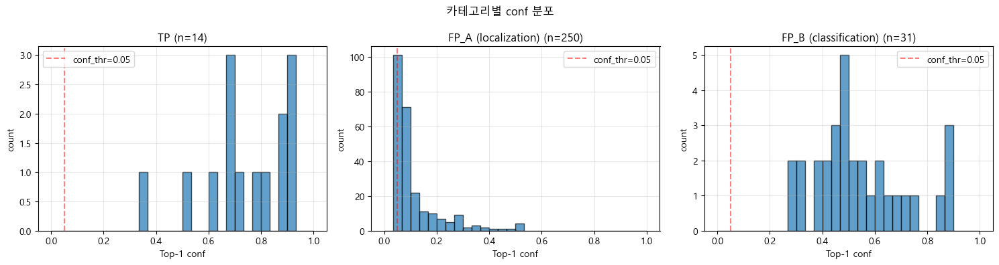


저장: D:\pill_detection\analysis\figures\fp_01_conf_distribution.png


In [5]:
## 셀 7 — IoU 매칭 + FP 두 종류 분류

def iou_xyxy(box1, box2):
    """두 박스의 IoU. 둘 다 [x1, y1, x2, y2]."""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    a1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    a2 = (box2[2]-box2[0]) * (box2[3]-box2[1])
    union = a1 + a2 - inter
    return inter / union if union > 0 else 0


# ── 매칭 + 분류 ──
records = []
for img_idx, r in enumerate(eval_data['results']):
    fname = r['filename']
    gts = r['gt_bboxes']
    preds = r['predictions']

    for pred_idx, p in enumerate(preds):
        pbox = p['bbox']
        top1_name = p['top3_class_name'][0]
        top1_conf = p['top3_confidence'][0]
        pred_w = pbox[2] - pbox[0]
        pred_h = pbox[3] - pbox[1]
        pred_cx = (pbox[0] + pbox[2]) / 2
        pred_cy = (pbox[1] + pbox[3]) / 2

        # GT와 최대 IoU
        best_iou = 0.0
        best_gt_idx = -1
        best_gt_name = None
        for gi, g in enumerate(gts):
            iou = iou_xyxy(pbox, g['bbox'])
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gi
                best_gt_name = g['dl_name']

        # 분류
        if best_iou >= 0.5:
            if top1_name == best_gt_name:
                category = 'TP'
            else:
                category = 'FP_B_class'
        elif best_iou < 0.3:
            category = 'FP_A_loc'
        else:
            category = 'GRAY_03_05'

        # GT가 0개인 이미지에서는 모든 예측이 FP_A
        if not gts:
            category = 'FP_A_loc'

        records.append({
            'img_idx': img_idx, 'filename': fname,
            'pred_idx': pred_idx,
            'pbox': pbox, 'pred_w': pred_w, 'pred_h': pred_h,
            'pred_cx': pred_cx, 'pred_cy': pred_cy,
            'top1_name': top1_name, 'top1_conf': top1_conf,
            'top3_names': p['top3_class_name'],
            'top3_confs': p['top3_confidence'],
            'best_iou': best_iou,
            'best_gt_idx': best_gt_idx,
            'best_gt_name': best_gt_name,
            'category': category,
        })

df_pred = pd.DataFrame(records)
print(f"총 예측 박스: {len(df_pred)}")


# ── 카테고리별 카운트 ──
print("\n[카테고리별 카운트]")
counts = df_pred['category'].value_counts()
for cat in ['TP', 'FP_A_loc', 'FP_B_class', 'GRAY_03_05']:
    cnt = counts.get(cat, 0)
    pct = cnt / len(df_pred) * 100
    print(f"  {cat:>15}: {cnt:>4} ({pct:>5.1f}%)")


# ── conf threshold별 FP 카운트 (얼마나 conf=0.05 저신뢰 박스가 많은가) ──
print("\n[conf threshold별 FP_A 카운트]")
fp_a = df_pred[df_pred['category']=='FP_A_loc']
print(f"  FP_A 전체: {len(fp_a)}")
for thr in [0.05, 0.1, 0.2, 0.3, 0.5]:
    n = (fp_a['top1_conf'] >= thr).sum()
    print(f"  conf >= {thr}: {n} ({n/len(fp_a)*100:.1f}%)")

print("\n[conf threshold별 FP_B 카운트]")
fp_b = df_pred[df_pred['category']=='FP_B_class']
print(f"  FP_B 전체: {len(fp_b)}")
for thr in [0.05, 0.1, 0.2, 0.3, 0.5]:
    n = (fp_b['top1_conf'] >= thr).sum()
    print(f"  conf >= {thr}: {n} ({n/len(fp_b)*100:.1f}%)")


# ── 박스 크기 통계 (FP_A vs TP 비교 — 손가락은 보통 작거나 길쭉) ──
print("\n[박스 크기 통계 (px)]")
for cat in ['TP', 'FP_A_loc', 'FP_B_class']:
    sub = df_pred[df_pred['category']==cat]
    if len(sub) == 0:
        continue
    areas = sub['pred_w'] * sub['pred_h']
    aspects = sub['pred_w'] / sub['pred_h']
    print(f"  {cat:>15}: area mean {areas.mean():>8.0f} median {areas.median():>8.0f} | "
          f"aspect(w/h) mean {aspects.mean():>5.2f} median {aspects.median():>5.2f}")


# ── conf 분포 시각 ──
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, cat, title in zip(
    axes,
    ['TP', 'FP_A_loc', 'FP_B_class'],
    ['TP', 'FP_A (localization)', 'FP_B (classification)']
):
    sub = df_pred[df_pred['category']==cat]
    ax.hist(sub['top1_conf'], bins=30, range=(0, 1), edgecolor='black', alpha=0.7)
    ax.axvline(0.05, color='red', linestyle='--', alpha=0.5, label='conf_thr=0.05')
    ax.set_title(f"{title} (n={len(sub)})")
    ax.set_xlabel('Top-1 conf')
    ax.set_ylabel('count')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("카테고리별 conf 분포", fontsize=12)
plt.tight_layout()
out = FIG_DIR / "fp_01_conf_distribution.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")

## 3. FP_A 250 전수 시각 — aspect 정렬

aspect 양극화(mean 1.92 / median 0.84) 패턴 의심. aspect 작은 것(세로 길쭉) ~ 큰 것(가로 길쭉) 순서로 정렬해서 50개씩 5페이지 그리드.

손가락은 보통 aspect 극단치 (≪1 또는 ≫1). 알약은 보통 0.7~1.5. aspect 분포 따라 패턴 클러스터링.

각 박스: 원본 이미지에서 박스 영역 crop + 박스 정보(conf, top1 class, aspect, area).

페이지마다 패턴 카테고리 메모: 손가락 / 그림자 / 배경 텍스처 / 알약 가장자리(IoU 부족) / 기타.

FP_A 정렬 완료: 250개, aspect 범위 [0.04, 22.32]

[aspect 분포]
  < 0.5 (세로 매우 긴): 94
  0.5~0.7 (세로 긴):    19
  0.7~1.5 (정상 비율):  72
  1.5~2.0 (가로 긴):    14
  >= 2.0 (가로 매우 긴): 51

페이지 수: 5


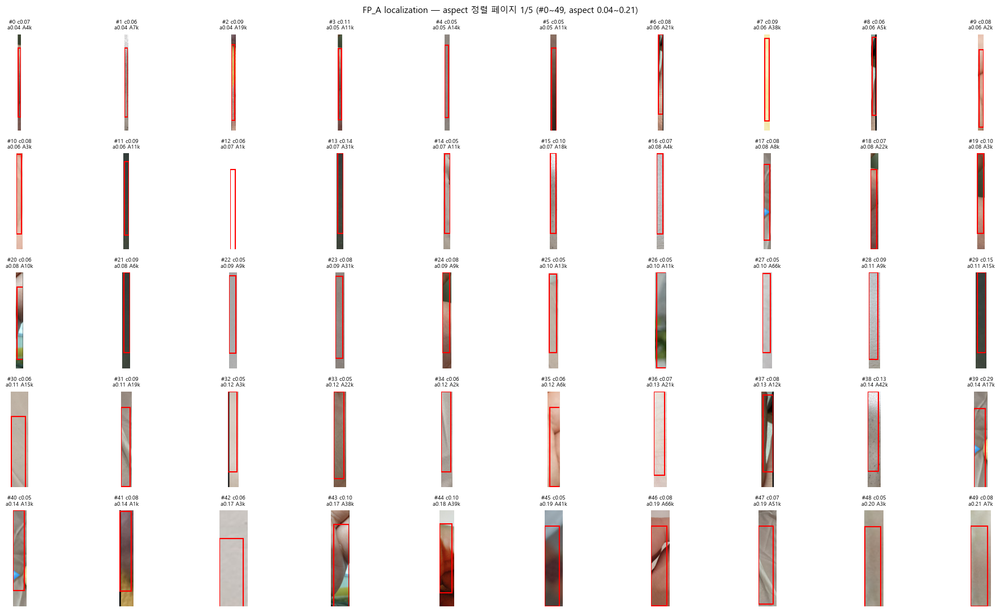

저장: D:\pill_detection\analysis\figures\fp_02_grid_aspect_p1.png


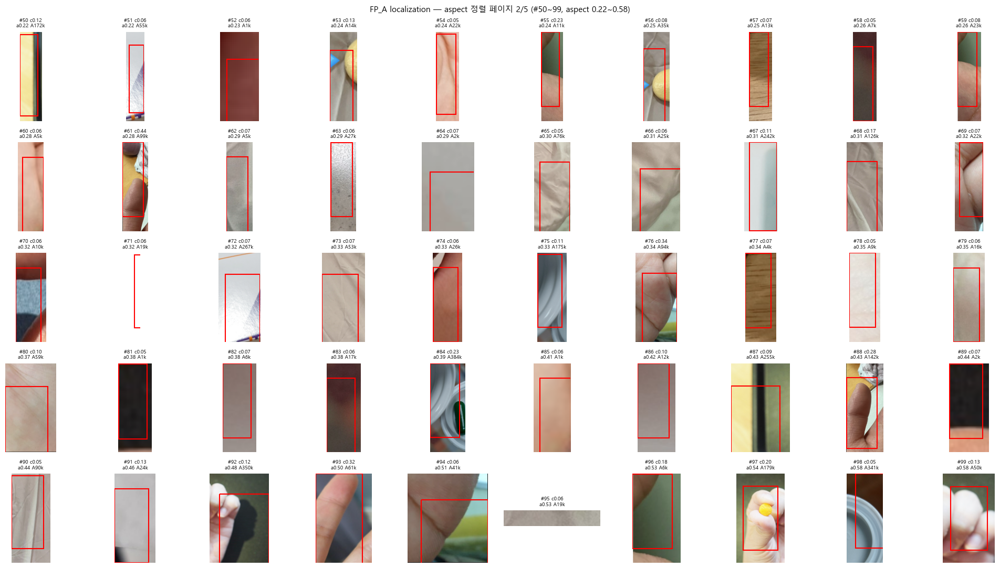

저장: D:\pill_detection\analysis\figures\fp_02_grid_aspect_p2.png
  [skip] #120 타이레놀500mg.png pbox=[389.1339111328125, 503.71563720703125, 531.3219604492188, 686.8887939453125] crop_coords=(361,468,559,336) img_shape=(336, 692, 3)
  [skip] #121 엔테론정 150mg.png pbox=[554.39111328125, 737.1865234375, 761.3050537109375, 1002.3016357421875] crop_coords=(513,684,802,458) img_shape=(458, 1007, 3)


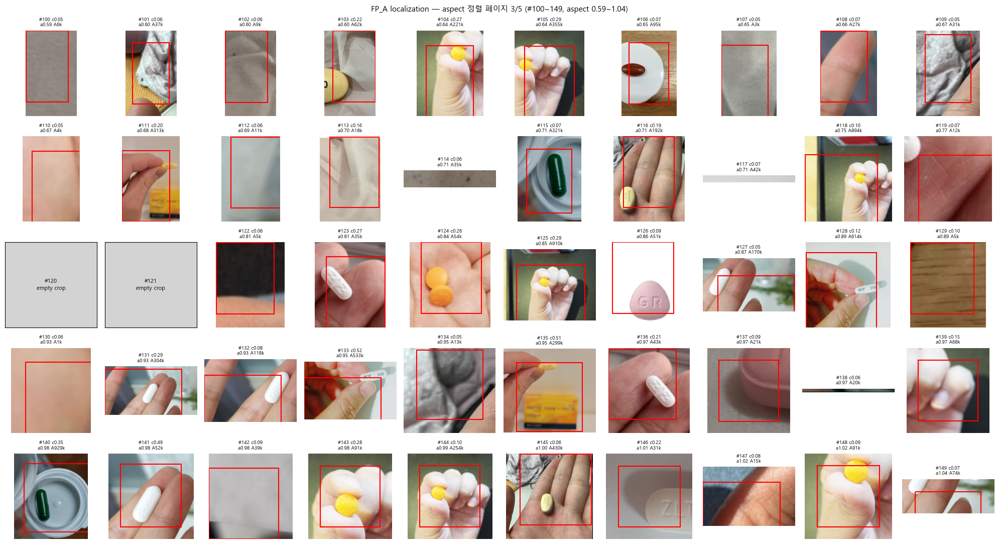

저장: D:\pill_detection\analysis\figures\fp_02_grid_aspect_p3.png


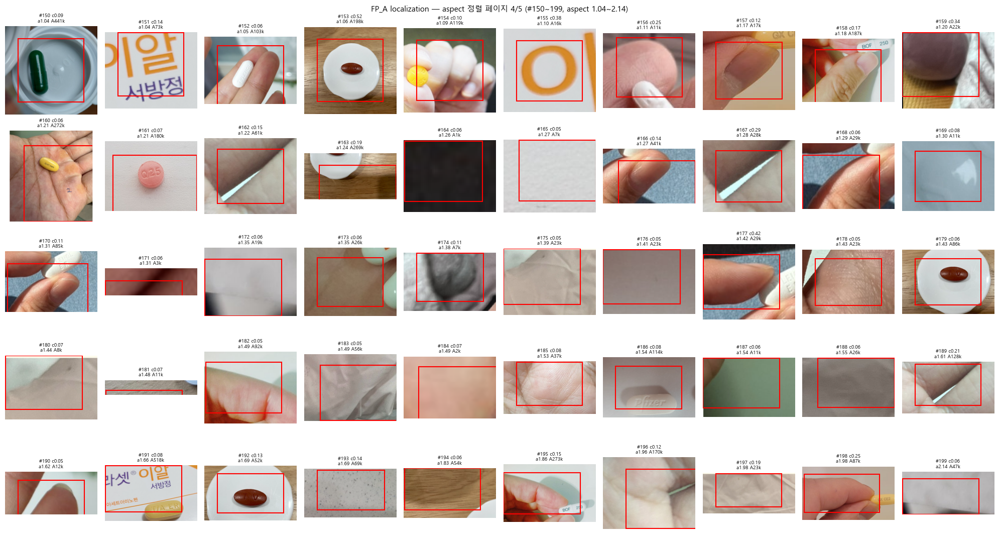

저장: D:\pill_detection\analysis\figures\fp_02_grid_aspect_p4.png


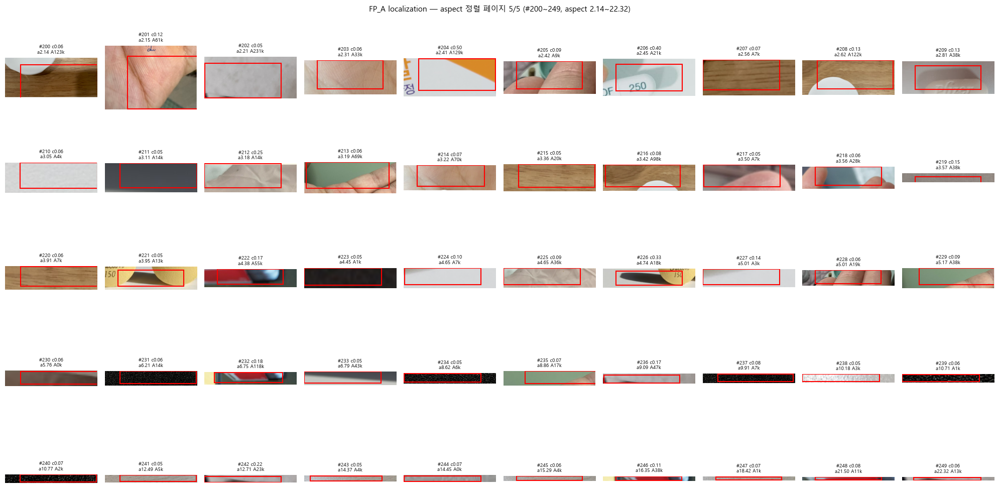

저장: D:\pill_detection\analysis\figures\fp_02_grid_aspect_p5.png


In [7]:
## 셀 9 — FP_A 250 aspect 정렬 시각 (5페이지)

fp_a_df = df_pred[df_pred['category']=='FP_A_loc'].copy()
fp_a_df['aspect'] = fp_a_df['pred_w'] / fp_a_df['pred_h']
fp_a_df['area'] = fp_a_df['pred_w'] * fp_a_df['pred_h']
fp_a_df = fp_a_df.sort_values('aspect').reset_index(drop=True)
print(f"FP_A 정렬 완료: {len(fp_a_df)}개, aspect 범위 [{fp_a_df['aspect'].min():.2f}, {fp_a_df['aspect'].max():.2f}]")

# aspect 분포 통계
print(f"\n[aspect 분포]")
print(f"  < 0.5 (세로 매우 긴): {(fp_a_df['aspect']<0.5).sum()}")
print(f"  0.5~0.7 (세로 긴):    {((fp_a_df['aspect']>=0.5)&(fp_a_df['aspect']<0.7)).sum()}")
print(f"  0.7~1.5 (정상 비율):  {((fp_a_df['aspect']>=0.7)&(fp_a_df['aspect']<1.5)).sum()}")
print(f"  1.5~2.0 (가로 긴):    {((fp_a_df['aspect']>=1.5)&(fp_a_df['aspect']<2.0)).sum()}")
print(f"  >= 2.0 (가로 매우 긴): {(fp_a_df['aspect']>=2.0).sum()}")


# ── 이미지 캐시 (33장 한번만 로드) ──
img_cache = {}
for r in eval_data['results']:
    img_path = TEST_IMG_DIR / r['filename']
    img_cache[r['filename']] = imread_kr(img_path)


# ── crop + 그리드 (페이지 분할) ──
COLS = 10
ROWS = 5
PER_PAGE = COLS * ROWS  # 50

n_pages = (len(fp_a_df) + PER_PAGE - 1) // PER_PAGE
print(f"\n페이지 수: {n_pages}")

for page in range(n_pages):
    fig, axes = plt.subplots(ROWS, COLS, figsize=(20, 11))
    start = page * PER_PAGE
    end = min(start + PER_PAGE, len(fp_a_df))

    for i in range(PER_PAGE):
        ax = axes[i // COLS, i % COLS]
        global_idx = start + i

        if global_idx >= end:
            ax.axis('off')
            continue

        row = fp_a_df.iloc[global_idx]
        img = img_cache[row['filename']]
        H, W = img.shape[:2]
        x1, y1, x2, y2 = [int(round(v)) for v in row['pbox']]

        # 컨텍스트 padding 20%
        bw, bh = x2-x1, y2-y1
        pad_x = int(bw * 0.2)
        pad_y = int(bh * 0.2)
        cx1 = max(0, x1 - pad_x)
        cy1 = max(0, y1 - pad_y)
        cx2 = min(W, x2 + pad_x)
        cy2 = min(H, y2 + pad_y)

        crop = img[cy1:cy2, cx1:cx2]

        # ── 가드: 빈 crop 처리 ──
        if crop.size == 0 or crop.shape[0] == 0 or crop.shape[1] == 0:
            print(f"  [skip] #{global_idx} {row['filename']} "
                  f"pbox={row['pbox']} crop_coords=({cx1},{cy1},{cx2},{cy2}) "
                  f"img_shape={img.shape}")
            ax.set_facecolor('lightgray')
            ax.text(0.5, 0.5, f"#{global_idx}\nempty crop",
                    ha='center', va='center', fontsize=8, transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
            continue

        crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

        # 박스를 crop 내 좌표로 그리기
        rect_x = x1 - cx1
        rect_y = y1 - cy1
        ax.imshow(crop_rgb)
        rect = patches.Rectangle((rect_x, rect_y), bw, bh,
                                  linewidth=1.5, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        ax.set_title(f"#{global_idx} c{row['top1_conf']:.2f}\n"
                     f"a{row['aspect']:.2f} A{int(row['area']/1000)}k",
                     fontsize=7)
        ax.axis('off')

    plt.suptitle(f"FP_A localization — aspect 정렬 페이지 {page+1}/{n_pages} "
                 f"(#{start}~{end-1}, aspect {fp_a_df.iloc[start]['aspect']:.2f}~{fp_a_df.iloc[end-1]['aspect']:.2f})",
                 fontsize=11)
    plt.tight_layout()

    out = FIG_DIR / f"fp_02_grid_aspect_p{page+1}.png"
    plt.savefig(out, dpi=110, bbox_inches='tight')
    plt.show()
    print(f"저장: {out}")

## 4. FP_A 자동 패턴 분류 (1차)

전수 시각 검토에서 4개 패턴 후보 발견:
- 이미지 가장자리 띠 (페이지 1, 5)
- 손가락/손바닥 (페이지 2-3 일부, 4 일부)
- 천 주름 / 나무 결 / 배경 텍스처
- 포장지 글자

자동 분류 기준은 위치(가장자리 거리) + aspect + 면적 + conf로 제한적 분류만 가능. 색/텍스처 분류는 본 노트북 범위 밖.

**1차 자동 분류 카테고리:**
- `edge_strip`: 박스 중심이 이미지 경계 5% 이내 + aspect 극단(<0.3 or >2.5)
- `elongated_off_edge`: aspect 극단인데 가장자리 아님 (천 주름/길쭉한 손가락 등)
- `normal_ratio`: aspect 0.7~1.4 (정상 알약 비율, 위치 무관)
- `medium_ratio`: 그 외 (aspect 0.3~0.7 또는 1.4~2.5)

분류 후 카테고리별 카운트 + 샘플 16개씩 시각으로 분류 정확성 검증.

이 셀의 한계: 손가락 vs 천 주름 자동 구분 불가. 시각 검토에서 본 것을 단순 정량화만 함.

[FP_A 자동 패턴 분류]
              edge_strip:   79 ( 31.6%)
      elongated_off_edge:   29 ( 11.6%)
            medium_ratio:   79 ( 31.6%)
            normal_ratio:   63 ( 25.2%)
                      합계: 250

[카테고리별 conf / area 통계]
              edge_strip: conf mean 0.077 median 0.070 | area mean 13,983 median 9,804
      elongated_off_edge: conf mean 0.125 median 0.084 | area mean 47,242 median 36,871
            medium_ratio: conf mean 0.117 median 0.071 | area mean 88,315 median 41,418
            normal_ratio: conf mean 0.154 median 0.095 | area mean 145,103 median 51,347


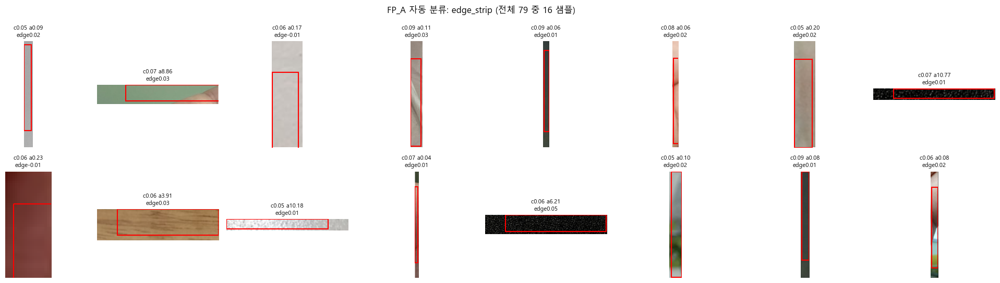

저장: D:\pill_detection\analysis\figures\fp_03_classified_edge_strip.png


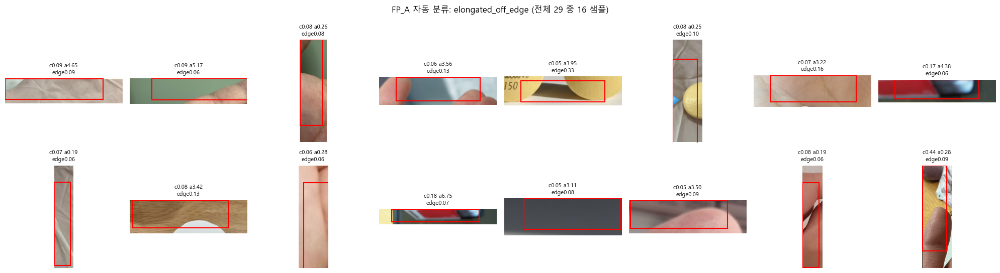

저장: D:\pill_detection\analysis\figures\fp_03_classified_elongated_off_edge.png


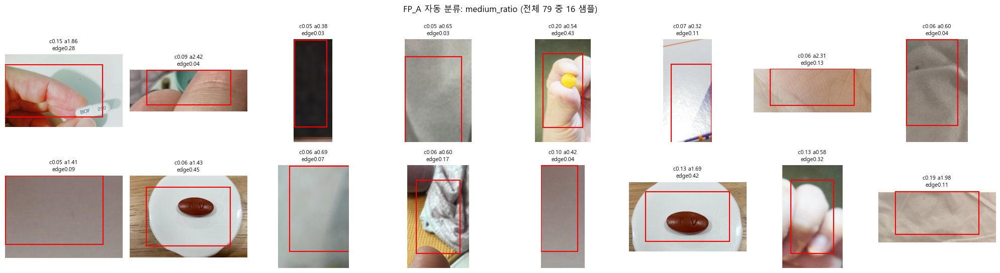

저장: D:\pill_detection\analysis\figures\fp_03_classified_medium_ratio.png


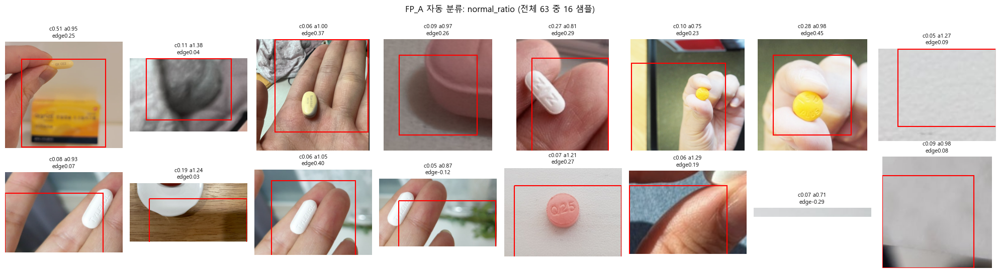

저장: D:\pill_detection\analysis\figures\fp_03_classified_normal_ratio.png


In [8]:
## 셀 11 — FP_A 자동 패턴 분류 (1차)

# ── 이미지 크기 정보 추가 (각 박스의 정규화 위치 계산용) ──
img_size_map = {r['filename']: img_cache[r['filename']].shape[:2] for r in eval_data['results']}

fp_a = df_pred[df_pred['category']=='FP_A_loc'].copy()
fp_a['img_h'] = fp_a['filename'].map(lambda f: img_size_map[f][0])
fp_a['img_w'] = fp_a['filename'].map(lambda f: img_size_map[f][1])
fp_a['aspect'] = fp_a['pred_w'] / fp_a['pred_h']
fp_a['area'] = fp_a['pred_w'] * fp_a['pred_h']

# 박스 중심의 가장자리 거리 (정규화)
fp_a['cx_norm'] = fp_a['pred_cx'] / fp_a['img_w']
fp_a['cy_norm'] = fp_a['pred_cy'] / fp_a['img_h']
fp_a['edge_dist'] = fp_a[['cx_norm', 'cy_norm']].apply(
    lambda r: min(r['cx_norm'], 1-r['cx_norm'], r['cy_norm'], 1-r['cy_norm']), axis=1
)


# ── 분류 함수 ──
def classify_pattern(row):
    a = row['aspect']
    edge = row['edge_dist']

    extreme_aspect = (a < 0.3) or (a > 2.5)
    medium_aspect = (0.3 <= a < 0.7) or (1.4 < a <= 2.5)
    normal_aspect = (0.7 <= a <= 1.4)

    if edge < 0.05 and extreme_aspect:
        return 'edge_strip'
    if extreme_aspect:
        return 'elongated_off_edge'
    if normal_aspect:
        return 'normal_ratio'
    return 'medium_ratio'

fp_a['pattern'] = fp_a.apply(classify_pattern, axis=1)


# ── 카운트 ──
print("[FP_A 자동 패턴 분류]")
pattern_counts = fp_a['pattern'].value_counts()
for pat in ['edge_strip', 'elongated_off_edge', 'medium_ratio', 'normal_ratio']:
    cnt = pattern_counts.get(pat, 0)
    pct = cnt / len(fp_a) * 100
    print(f"  {pat:>22}: {cnt:>4} ({pct:>5.1f}%)")
print(f"  {'합계':>22}: {len(fp_a)}")


# ── 카테고리별 통계 ──
print("\n[카테고리별 conf / area 통계]")
for pat in ['edge_strip', 'elongated_off_edge', 'medium_ratio', 'normal_ratio']:
    sub = fp_a[fp_a['pattern']==pat]
    if len(sub) == 0:
        continue
    print(f"  {pat:>22}: conf mean {sub['top1_conf'].mean():.3f} median {sub['top1_conf'].median():.3f} | "
          f"area mean {int(sub['area'].mean()):,} median {int(sub['area'].median()):,}")


# ── 카테고리별 샘플 16개 시각 (분류 정확성 검증) ──
SAMPLE_PER_CAT = 16
COLS = 8
ROWS = 2

for pat in ['edge_strip', 'elongated_off_edge', 'medium_ratio', 'normal_ratio']:
    sub = fp_a[fp_a['pattern']==pat]
    if len(sub) == 0:
        print(f"\n[{pat}] 0개, 스킵")
        continue

    n_show = min(SAMPLE_PER_CAT, len(sub))
    rng_s = np.random.default_rng(42)
    sample_idx = rng_s.choice(len(sub), n_show, replace=False)

    fig, axes = plt.subplots(ROWS, COLS, figsize=(20, 5.5))
    for i in range(ROWS * COLS):
        ax = axes[i // COLS, i % COLS]
        if i >= n_show:
            ax.axis('off')
            continue

        row = sub.iloc[sample_idx[i]]
        img = img_cache[row['filename']]
        H, W = img.shape[:2]
        x1, y1, x2, y2 = [int(round(v)) for v in row['pbox']]
        bw, bh = x2-x1, y2-y1
        pad_x, pad_y = int(bw*0.2), int(bh*0.2)
        cx1 = max(0, x1-pad_x); cy1 = max(0, y1-pad_y)
        cx2 = min(W, x2+pad_x); cy2 = min(H, y2+pad_y)

        crop = img[cy1:cy2, cx1:cx2]
        if crop.size == 0:
            ax.set_facecolor('lightgray')
            ax.set_xticks([]); ax.set_yticks([])
            continue

        crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        ax.imshow(crop_rgb)
        rect = patches.Rectangle((x1-cx1, y1-cy1), bw, bh, linewidth=1.5, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        ax.set_title(f"c{row['top1_conf']:.2f} a{row['aspect']:.2f}\nedge{row['edge_dist']:.2f}",
                     fontsize=8)
        ax.axis('off')

    plt.suptitle(f"FP_A 자동 분류: {pat} (전체 {len(sub)} 중 {n_show} 샘플)", fontsize=12)
    plt.tight_layout()

    out = FIG_DIR / f"fp_03_classified_{pat}.png"
    plt.savefig(out, dpi=110, bbox_inches='tight')
    plt.show()
    print(f"저장: {out}")

## 5. FP_A 위치 분포 히트맵 (B)

자동 분류에서 edge_strip 31.6% 확인. 박스 중심점 분포로 가장자리 패턴 정량 검증.

**시각:**
- 2D scatter: 모든 FP_A 박스 중심점 (cx_norm, cy_norm) — 카테고리별 색
- 2D heatmap: 박스 중심점 밀도 (가장자리 집중도 시각)
- 4면 가장자리별 거리 분포 — 어느 가장자리에 더 많이 몰리는가

비교: TP 박스 위치 분포도 같이 표시 → FP_A 분포가 TP와 어떻게 다른지.

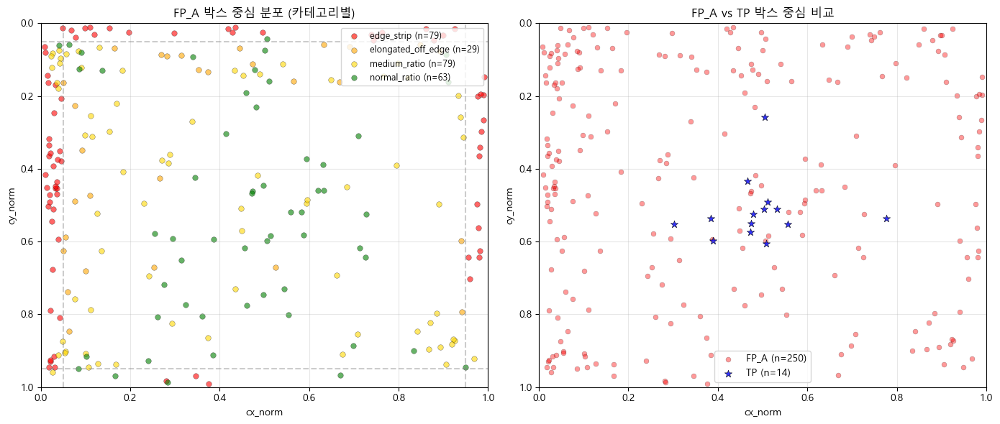

저장: D:\pill_detection\analysis\figures\fp_04_scatter_position.png


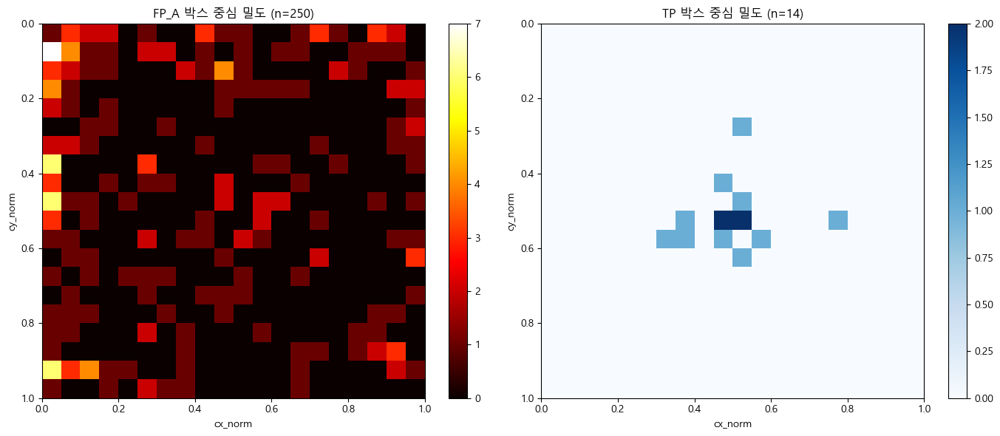

저장: D:\pill_detection\analysis\figures\fp_05_heatmap.png

[4면 가장자리별 박스 중심 거리 분포 (정규화, 0=가장자리)]
  좌:   median 0.346, 5% 이내 50개
  우:   median 0.654, 5% 이내 18개
  상:   median 0.451, 5% 이내 24개
  하:   median 0.549, 5% 이내 23개

  어느 한 면이라도 5% 이내: 110/250 (44.0%)
  어느 한 면이라도 10% 이내: 161/250 (64.4%)


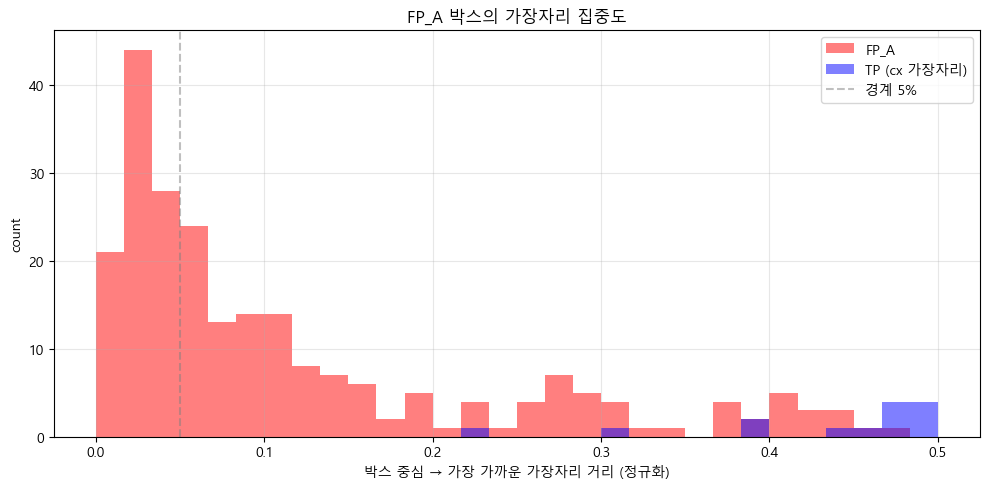

저장: D:\pill_detection\analysis\figures\fp_06_edge_distance_hist.png


In [9]:
## 셀 13 — FP_A 위치 분포 히트맵

# TP 박스에도 위치 정보 추가
tp = df_pred[df_pred['category']=='TP'].copy()
tp['img_h'] = tp['filename'].map(lambda f: img_size_map[f][0])
tp['img_w'] = tp['filename'].map(lambda f: img_size_map[f][1])
tp['cx_norm'] = tp['pred_cx'] / tp['img_w']
tp['cy_norm'] = tp['pred_cy'] / tp['img_h']


# ── 시각 1: scatter (FP_A 카테고리별 색 + TP 비교) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
colors = {'edge_strip': 'red', 'elongated_off_edge': 'orange',
          'medium_ratio': 'gold', 'normal_ratio': 'green'}
for pat, color in colors.items():
    sub = fp_a[fp_a['pattern']==pat]
    ax.scatter(sub['cx_norm'], sub['cy_norm'], c=color, label=f"{pat} (n={len(sub)})",
               alpha=0.6, s=30, edgecolors='black', linewidths=0.3)
ax.set_xlim(0, 1); ax.set_ylim(1, 0)  # y 뒤집기 (이미지 좌표)
ax.set_xlabel('cx_norm'); ax.set_ylabel('cy_norm')
ax.set_title('FP_A 박스 중심 분포 (카테고리별)')
ax.axhline(0.05, color='gray', linestyle='--', alpha=0.4)
ax.axhline(0.95, color='gray', linestyle='--', alpha=0.4)
ax.axvline(0.05, color='gray', linestyle='--', alpha=0.4)
ax.axvline(0.95, color='gray', linestyle='--', alpha=0.4)
ax.legend(fontsize=9, loc='upper right')
ax.grid(alpha=0.3)

ax = axes[1]
ax.scatter(fp_a['cx_norm'], fp_a['cy_norm'], c='red', label=f"FP_A (n={len(fp_a)})",
           alpha=0.4, s=25, edgecolors='black', linewidths=0.3)
ax.scatter(tp['cx_norm'], tp['cy_norm'], c='blue', label=f"TP (n={len(tp)})",
           alpha=0.8, s=60, marker='*', edgecolors='black', linewidths=0.5)
ax.set_xlim(0, 1); ax.set_ylim(1, 0)
ax.set_xlabel('cx_norm'); ax.set_ylabel('cy_norm')
ax.set_title('FP_A vs TP 박스 중심 비교')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
out = FIG_DIR / "fp_04_scatter_position.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out}")


# ── 시각 2: 2D heatmap (FP_A 밀도) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
h = ax.hist2d(fp_a['cx_norm'], fp_a['cy_norm'], bins=20, range=[[0,1],[0,1]], cmap='hot')
ax.invert_yaxis()
ax.set_xlabel('cx_norm'); ax.set_ylabel('cy_norm')
ax.set_title(f'FP_A 박스 중심 밀도 (n={len(fp_a)})')
plt.colorbar(h[3], ax=ax)

ax = axes[1]
h2 = ax.hist2d(tp['cx_norm'], tp['cy_norm'], bins=20, range=[[0,1],[0,1]], cmap='Blues')
ax.invert_yaxis()
ax.set_xlabel('cx_norm'); ax.set_ylabel('cy_norm')
ax.set_title(f'TP 박스 중심 밀도 (n={len(tp)})')
plt.colorbar(h2[3], ax=ax)

plt.tight_layout()
out = FIG_DIR / "fp_05_heatmap.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out}")


# ── 4면 가장자리별 거리 분포 ──
print("\n[4면 가장자리별 박스 중심 거리 분포 (정규화, 0=가장자리)]")
fp_a['dist_left']   = fp_a['cx_norm']
fp_a['dist_right']  = 1 - fp_a['cx_norm']
fp_a['dist_top']    = fp_a['cy_norm']
fp_a['dist_bottom'] = 1 - fp_a['cy_norm']

print(f"  좌:   median {fp_a['dist_left'].median():.3f}, 5% 이내 {(fp_a['dist_left']<0.05).sum()}개")
print(f"  우:   median {fp_a['dist_right'].median():.3f}, 5% 이내 {(fp_a['dist_right']<0.05).sum()}개")
print(f"  상:   median {fp_a['dist_top'].median():.3f}, 5% 이내 {(fp_a['dist_top']<0.05).sum()}개")
print(f"  하:   median {fp_a['dist_bottom'].median():.3f}, 5% 이내 {(fp_a['dist_bottom']<0.05).sum()}개")

# 어느 한 면이라도 5% 이내
n_any_edge = ((fp_a['dist_left']<0.05) | (fp_a['dist_right']<0.05) |
              (fp_a['dist_top']<0.05) | (fp_a['dist_bottom']<0.05)).sum()
n_any_10 = ((fp_a['dist_left']<0.10) | (fp_a['dist_right']<0.10) |
            (fp_a['dist_top']<0.10) | (fp_a['dist_bottom']<0.10)).sum()
print(f"\n  어느 한 면이라도 5% 이내: {n_any_edge}/{len(fp_a)} ({n_any_edge/len(fp_a)*100:.1f}%)")
print(f"  어느 한 면이라도 10% 이내: {n_any_10}/{len(fp_a)} ({n_any_10/len(fp_a)*100:.1f}%)")


# ── histogram: 가장자리 거리 분포 ──
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.hist(fp_a['edge_dist'], bins=30, range=(0, 0.5), color='red', alpha=0.5, label='FP_A')
ax.hist(tp['cx_norm'].apply(lambda x: min(x, 1-x)), bins=30, range=(0, 0.5),
        color='blue', alpha=0.5, label='TP (cx 가장자리)')
ax.axvline(0.05, color='gray', linestyle='--', alpha=0.5, label='경계 5%')
ax.set_xlabel('박스 중심 → 가장 가까운 가장자리 거리 (정규화)')
ax.set_ylabel('count')
ax.set_title('FP_A 박스의 가장자리 집중도')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

out = FIG_DIR / "fp_06_edge_distance_hist.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out}")

## 6. FP_A conf 정렬 시각 (C)

위치 분석 끝. 마지막 검증: 높은 conf FP_A 박스가 어떤 패턴인가.

높은 conf = 모델이 "확신하고 틀림" → 학습 실패의 직접 증거. 위험도 높음. conf threshold 상향으로 제거 안 됨.

conf 내림차순 정렬, 상위 50개를 한 페이지에 시각.

FP_A conf 분포: max 0.516, top10 mean 0.451


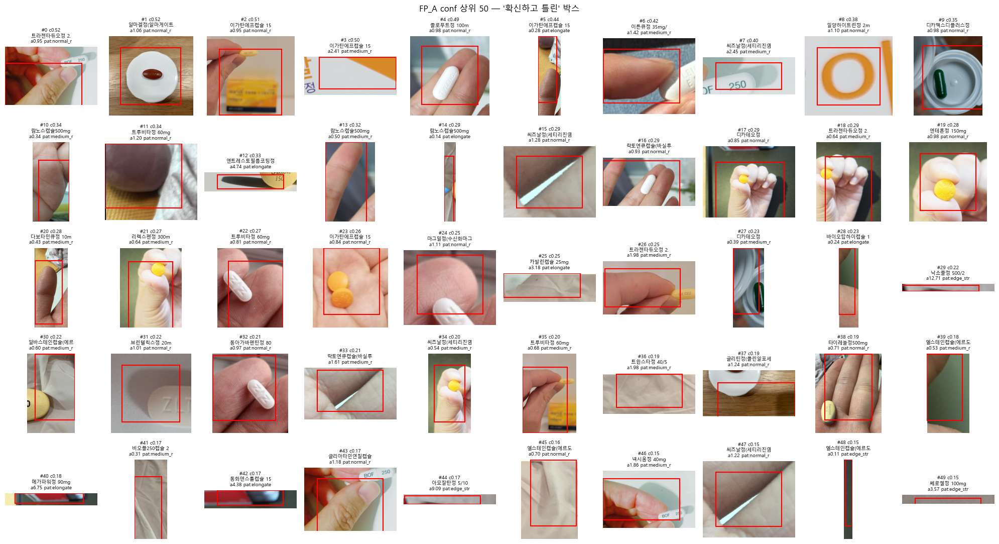

저장: D:\pill_detection\analysis\figures\fp_07_top50_by_conf.png

[conf >= 0.2 FP_A의 패턴 분포]
  전체: 35개
            normal_ratio: 16
            medium_ratio: 13
      elongated_off_edge: 5
              edge_strip: 1

[conf >= 0.3]
  전체: 14개
            normal_ratio: 7
            medium_ratio: 5
      elongated_off_edge: 2


In [10]:
## 셀 15 — FP_A conf 내림차순 시각 (상위 50)

fp_a_by_conf = fp_a.sort_values('top1_conf', ascending=False).reset_index(drop=True)
print(f"FP_A conf 분포: max {fp_a_by_conf['top1_conf'].max():.3f}, "
      f"top10 mean {fp_a_by_conf['top1_conf'].head(10).mean():.3f}")


COLS = 10
ROWS = 5
N_SHOW = 50

fig, axes = plt.subplots(ROWS, COLS, figsize=(20, 11))
for i in range(ROWS * COLS):
    ax = axes[i // COLS, i % COLS]
    if i >= N_SHOW:
        ax.axis('off')
        continue

    row = fp_a_by_conf.iloc[i]
    img = img_cache[row['filename']]
    H, W = img.shape[:2]
    x1, y1, x2, y2 = [int(round(v)) for v in row['pbox']]
    bw, bh = x2-x1, y2-y1
    pad_x, pad_y = int(bw*0.2), int(bh*0.2)
    cx1 = max(0, x1-pad_x); cy1 = max(0, y1-pad_y)
    cx2 = min(W, x2+pad_x); cy2 = min(H, y2+pad_y)

    crop = img[cy1:cy2, cx1:cx2]
    if crop.size == 0:
        ax.set_facecolor('lightgray')
        ax.text(0.5, 0.5, "empty", ha='center', va='center', transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        continue

    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    ax.imshow(crop_rgb)
    rect = patches.Rectangle((x1-cx1, y1-cy1), bw, bh,
                              linewidth=1.5, edgecolor='red', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(f"#{i} c{row['top1_conf']:.2f}\n{row['top1_name'][:10]}\n"
                 f"a{row['aspect']:.2f} pat:{row['pattern'][:8]}",
                 fontsize=7)
    ax.axis('off')

plt.suptitle(f"FP_A conf 상위 50 — '확신하고 틀린' 박스", fontsize=12)
plt.tight_layout()

out = FIG_DIR / "fp_07_top50_by_conf.png"
plt.savefig(out, dpi=110, bbox_inches='tight')
plt.show()
print(f"저장: {out}")


# ── conf >= 0.2 박스의 패턴 분포 ──
print("\n[conf >= 0.2 FP_A의 패턴 분포]")
high_conf = fp_a[fp_a['top1_conf'] >= 0.2]
print(f"  전체: {len(high_conf)}개")
for pat, cnt in high_conf['pattern'].value_counts().items():
    print(f"  {pat:>22}: {cnt}")

print(f"\n[conf >= 0.3]")
print(f"  전체: {(fp_a['top1_conf']>=0.3).sum()}개")
for pat, cnt in fp_a[fp_a['top1_conf']>=0.3]['pattern'].value_counts().items():
    print(f"  {pat:>22}: {cnt}")

## 7. 종합 — FP_A 250 패턴 분석 결과

### 카테고리별 카운트 (자동 분류)

| 카테고리 | 개수 | 비율 | conf mean | area median |
|---|---|---|---|---|
| edge_strip | 79 | 31.6% | 0.077 | 9,804 |
| elongated_off_edge | 29 | 11.6% | 0.125 | 36,871 |
| medium_ratio | 79 | 31.6% | 0.117 | 41,418 |
| normal_ratio | 63 | 25.2% | 0.154 | 51,347 |

### 위치 분포

- 박스 중심이 이미지 가장자리 5% 이내: **110/250 (44.0%)**
- 10% 이내: **161/250 (64.4%)**
- 좌측 가장자리 5% 이내 50개 vs 우측 18개 — 좌측 비대칭
- TP 14개는 모두 이미지 중앙(cx 0.4~0.6, cy 0.4~0.6)에 집중

### conf 상위 50 시각 검토 (사람 눈)

자동 분류는 위치/aspect 기준이라 한계. 시각 검토 결과:
- **온전한 알약 박스**: ~8개 (3%) — 평가 매칭 의심 가능
- **알약 일부만 / 살짝 걸침**: 상당수 — bbox regression 부족
- **손가락/손바닥 자체 박스**: 다수 — 학습 실패의 직접 증거 (conf 0.2~0.34)
- **단색 배경 띠**: 소수 — threshold로 처리 가능

### 진단 셀 27 한계 보강 결과

진단에서 "손가락 = 핵심 패턴"으로 16개 본 결과. 전수 250 본 결과:
- 손가락 자체는 medium_ratio + normal_ratio 일부에 분산. 정량 비율은 본 노트북의 자동 분류로 정확히 측정 불가 (색/텍스처 분류 불능).
- **edge_strip 31.6%가 손가락보다 큰 단일 카테고리**. 진단에서 놓친 패턴.
- 추가 발견: 약 포장지 글자 ("이알", "Pfizer", "Q25" 등), 나무 결, 천 주름 등.

### conf threshold 영향

| threshold | FP_A 잔존 |
|---|---|
| 0.05 | 250 (100%) |
| 0.1 | 78 (31.2%) |
| 0.2 | 35 (14.0%) |
| 0.3 | 14 (5.6%) |

threshold 0.1로 올리면 자동 1/3 감소. 단 학습 개선 없이 threshold만 올리면 recall도 떨어짐 (현재 TP=14, conf 분포 0.35~0.95).

### 처방 시사점

1. **처방 4 (배경 풀 재구성)** — 손가락/손바닥/포장지/나무 결 다양화. 기존 "palm 30~50장+"에서 카테고리별 균등 확장으로 변경.
2. **letterbox padding 또는 가장자리 augmentation** — FP_A 64% 가장자리 집중 패턴 처리. 학습 시 알약을 가장자리 가까이 배치하거나 letterbox 적용.
3. **conf threshold 0.1로 검토** — 평가 시 빠른 효과 확인 가능. 단 recall trade-off 측정 필요.
4. **bbox regression 개선** — "알약 살짝 걸침" 패턴은 imgsz 1280 + 합성 데이터 다양화로 자동 개선 기대 (단계 2-B 처방 1과 연동).

### 측정 한계

1. 자동 분류는 위치/aspect만 사용. 색/텍스처 분류 불가.
2. "온전한 알약 8개"가 GT 라벨 누락인지 평가 매칭 로직 문제인지 본 노트북에서 검증 안 함.
3. 33장 테스트셋 결과. 일반화 가능성은 측정 안 함.

### 산출 figure

- fp_01_conf_distribution.png — 카테고리별 conf 분포
- fp_02_grid_aspect_p1~p5.png — 250개 전수 시각 (5페이지, aspect 정렬)
- fp_03_classified_*.png — 자동 분류 4 카테고리 샘플
- fp_04_scatter_position.png — FP_A vs TP 위치 scatter
- fp_05_heatmap.png — 박스 중심 밀도 히트맵
- fp_06_edge_distance_hist.png — 가장자리 거리 분포
- fp_07_top50_by_conf.png — conf 상위 50 (학습 실패 직접 증거)